In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import json
import shutil
import hashlib
from tqdm import tqdm
from PIL import Image
from collections import Counter
import yaml

In [ ]:
# --- CONFIGURATION ---
# Base path to the COCO dataset on Drive
BASE_PATH = "/content/drive/MyDrive/CarDD_release_Damages/CarDD_COCO"
# Fast local storage path for training
OUTPUT_PATH = "/content/CarDD_YOLO"

In [ ]:
def convert_coco_to_yolo(split_name, img_folder, json_file):
    """
    Reads COCO JSON and saves images/labels in YOLO SEGMENTATION format.
    Format: class_id x1 y1 x2 y2 ... xn yn (normalized)
    """
    images_src = os.path.join(BASE_PATH, img_folder)
    ann_src = os.path.join(BASE_PATH, "annotations", json_file)

    # Validate paths before processing
    if not os.path.exists(images_src) or not os.path.exists(ann_src):
        print(f"Missing source files for: {split_name}")
        return []

    with open(ann_src) as f:
        coco = json.load(f)

    # Create dynamic class mapping to ensure IDs are 0-indexed
    cat_map = {cat['id']: i for i, cat in enumerate(coco['categories'])}
    class_names = [cat['name'] for cat in coco['categories']]

    # Create the standard YOLO directory structure
    os.makedirs(os.path.join(OUTPUT_PATH, split_name, "images"), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_PATH, split_name, "labels"), exist_ok=True)

    # Group annotations by image ID
    images_info = {img["id"]: img for img in coco["images"]}
    annotations_map = {}
    for ann in coco["annotations"]:
        annotations_map.setdefault(ann["image_id"], []).append(ann)

    print(f"Processing Segmentation Split: {split_name}")
    for image_id, img_info in tqdm(images_info.items()):
        if image_id not in annotations_map: continue

        img_file = img_info["file_name"]
        img_path = os.path.join(images_src, img_file)

        # Basic image integrity check and size retrieval
        try:
            img = Image.open(img_path)
            w, h = img.size
        except: continue

        yolo_lines = []
        for ann in annotations_map[image_id]:
            # --- START SEGMENTATION CONVERSION ---
            if 'segmentation' in ann and ann['segmentation']:
                # COCO 'segmentation' is usually a list of lists [[x1, y1, x2, y2...]]
                # We take the largest polygon if multiple exist for one object
                for seg in ann['segmentation']:
                    if len(seg) < 6: continue # Skip invalid polygons (need 3+ points)

                    # Normalize the coordinates
                    normalized_coords = []
                    for i in range(0, len(seg), 2):
                        nx = seg[i] / w
                        ny = seg[i+1] / h
                        # Clip to [0, 1] to prevent out-of-bounds errors
                        normalized_coords.append(max(0.0, min(1.0, nx)))
                        normalized_coords.append(max(0.0, min(1.0, ny)))

                    # Map original category ID to 0-indexed class ID
                    class_id = cat_map[ann["category_id"]]

                    # YOLO Segmentation format: class x1 y1 x2 y2 ...
                    coords_str = " ".join([f"{c:.6f}" for c in normalized_coords])
                    yolo_lines.append(f"{class_id} {coords_str}")
            # --- END SEGMENTATION CONVERSION ---

        # Only copy the image if at least one valid segmentation mask exists
        if yolo_lines:
            shutil.copy(img_path, os.path.join(OUTPUT_PATH, split_name, "images", img_file))
            label_name = os.path.splitext(img_file)[0] + ".txt"
            with open(os.path.join(OUTPUT_PATH, split_name, "labels", label_name), "w") as f:
                f.write("\n".join(yolo_lines))

    return class_names

# Execute the conversion for Train, Val, and Test splits
configs = [
    ("train", "train2017", "instances_train2017.json"),
    ("val", "val2017", "instances_val2017.json"),
    ("test", "test2017", "instances_test2017.json")
]

last_classes = []
for split, img_f, json_f in configs:
    classes = convert_coco_to_yolo(split, img_f, json_f)
    if classes: last_classes = classes

Processing Segmentation Split: train


100%|██████████| 2816/2816 [25:11<00:00,  1.86it/s]


Processing Segmentation Split: val


100%|██████████| 810/810 [07:02<00:00,  1.92it/s]


Processing Segmentation Split: test


100%|██████████| 374/374 [03:09<00:00,  1.97it/s]


In [ ]:
import random

def add_background_images(split_name, img_folder, limit=50):
    """
    Copies a few images that have NO annotations to act as background samples.
    """
    images_src = os.path.join(BASE_PATH, img_folder)
    dest_img_dir = os.path.join(OUTPUT_PATH, split_name, "images")
    dest_lab_dir = os.path.join(OUTPUT_PATH, split_name, "labels")

    # Get images already processed
    processed_images = set(os.listdir(dest_img_dir))
    all_images = [f for f in os.listdir(images_src) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    # Find images that were skipped because they had no labels
    background_candidates = [f for f in all_images if f not in processed_images]

    # Randomly pick a few
    sample_size = min(len(background_candidates), limit)
    bg_samples = random.sample(background_candidates, sample_size)

    print(f"Adding {sample_size} background images to {split_name}...")
    for img_file in bg_samples:
        shutil.copy(os.path.join(images_src, img_file), os.path.join(dest_img_dir, img_file))
        # Create an empty label file for background images
        label_name = os.path.splitext(img_file)[0] + ".txt"
        open(os.path.join(dest_lab_dir, label_name), 'a').close()

# Add background images to Train and Val
add_background_images("train", "train2017", limit=100)
add_background_images("val", "val2017", limit=20)

Adding 0 background images to train...
Adding 0 background images to val...


In [ ]:
def cleanup_and_verify():
    """
    1. Removes duplicate images using MD5 hashing.
    2. Counts occurrences of each class to check for dataset balance.
    """
    for split in ["train", "val", "test"]:
        img_dir = os.path.join(OUTPUT_PATH, split, "images")
        lab_dir = os.path.join(OUTPUT_PATH, split, "labels")

        if not os.path.exists(img_dir):
            print(f"{split} folder not found. Skipping...")
            continue

        # --- PART 1: DUPLICATE REMOVAL ---
        hashes = {}
        duplicates = 0
        for file in os.listdir(img_dir):
            path = os.path.join(img_dir, file)
            # Read image in binary mode to generate a unique hash
            with open(path, "rb") as f:
                h = hashlib.md5(f.read()).hexdigest()

            if h in hashes:
                # Remove duplicate image from local storage
                os.remove(path)
                # Remove corresponding label file to keep data synced
                lab_file = os.path.join(lab_dir, os.path.splitext(file)[0] + ".txt")
                if os.path.exists(lab_file):
                    os.remove(lab_file)
                duplicates += 1
            else:
                hashes[h] = file

        # --- PART 2: CLASS DISTRIBUTION CHECK ---
        class_counter = Counter()
        for label_file in os.listdir(lab_dir):
            with open(os.path.join(lab_dir, label_file), 'r') as f:
                for line in f:
                    # YOLO format: class_id x_center y_center width height
                    class_id = int(line.split()[0])
                    class_counter[class_id] += 1

        # Print results
        print(f"--- {split.upper()} SPLIT SUMMARY ---")
        print(f"Duplicates Removed: {duplicates}")
        print(f"Class Distribution: {dict(sorted(class_counter.items()))}")
        print("-" * 30)

# Run the cleaning and verification process
cleanup_and_verify()

--- TRAIN SPLIT SUMMARY ---
Duplicates Removed: 0
Class Distribution: {0: 1806, 1: 2560, 2: 651, 3: 475, 4: 494, 5: 225}
------------------------------
--- VAL SPLIT SUMMARY ---
Duplicates Removed: 0
Class Distribution: {0: 501, 1: 728, 2: 177, 3: 135, 4: 141, 5: 62}
------------------------------
--- TEST SPLIT SUMMARY ---
Duplicates Removed: 0
Class Distribution: {0: 236, 1: 307, 2: 70, 3: 71, 4: 69, 5: 32}
------------------------------


In [ ]:
def verify_and_clip_labels():
    """
    Ensures all YOLO coordinates are strictly between 0 and 1.
    """
    print("Verifying label integrity...")
    for split in ["train", "val", "test"]:
        lab_dir = os.path.join(OUTPUT_PATH, split, "labels")
        if not os.path.exists(lab_dir): continue

        for file in os.listdir(lab_dir):
            path = os.path.join(lab_dir, file)
            with open(path, 'r') as f:
                lines = f.readlines()

            new_lines = []
            for line in lines:
                parts = line.split()
                if len(parts) < 5: continue

                cls = parts[0]
                # Clip coordinates to [0.0, 1.0]
                coords = [max(0.0, min(1.0, float(x))) for x in parts[1:]]
                new_lines.append(f"{cls} {' '.join([f'{c:.6f}' for c in coords])}")

            with open(path, 'w') as f:
                f.write('\n'.join(new_lines))
    print("All labels verified and clipped.")

verify_and_clip_labels()

Verifying label integrity...
All labels verified and clipped.


In [ ]:
# Create the dictionary for YOLO configuration
data_config = {
    'path': OUTPUT_PATH,
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'nc': len(last_classes),
    'names': last_classes
}

# Save the configuration as a .yaml file
with open(os.path.join(OUTPUT_PATH, "data.yaml"), "w") as f:
    yaml.dump(data_config, f)

print("data.yaml created successfully!")

data.yaml created successfully!


In [ ]:
# Install the engine
!pip install ultralytics
from ultralytics import YOLO

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 28.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
import os
from ultralytics import YOLO

# 1. Check if the "last.pt" file already exists
weights_path = "/content/drive/MyDrive/CarDD_v11_Results/car_damage_balanced_run/weights/last.pt"

if os.path.exists(weights_path):
    # If it exists, load it and set resume to True
    model = YOLO(weights_path)
    resume_flag = True
else:
    # If it doesn't exist, start fresh and set resume to False
    model = YOLO("yolo11m-seg.pt")
    resume_flag = False

# Start Training with Class Imbalance Fixes
model.train(
    data="/content/CarDD_YOLO/data.yaml",
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    task='segment',
    resume=resume_flag,    # <--- Added this to handle the resume

    # --- Advanced Tuning ---
    overlap_mask=True,
    box=7.5,
    cls=1.5,

    # --- Augmentations (class imbalance fixes) ---
    augment=True,
    mosaic=0.8,
    mixup=0.1,
    copy_paste=0.3,
    hsv_h=0.015,
    project="/content/drive/MyDrive/CarDD_v11_Results",
    name="car_damage_balanced_run",
    exist_ok=True           # <--- Added this so it doesn't create a new folder
)

Ultralytics 8.4.19 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=1.5, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CarDD_YOLO/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/content/drive/MyDrive/CarDD_v11_Results/car_damage_balanced_run/weights/last.pt, momentum=0.937, mosaic=0.8, multi_scale=0.0, name=car_damage_balanced_run, nbs=64, nms=False, op

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a21239a3da0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004

In [ ]:
#   FINE-TUNING
#   Goal: Improve crack / scratch / dent detection

import os
from ultralytics import YOLO

# paths
best_weights = "/content/drive/MyDrive/CarDD_v11_Results/car_damage_balanced_run/weights/best.pt"
yaml_path    = "/content/CarDD_YOLO/data.yaml"
save_project = "/content/drive/MyDrive/CarDD_v11_Results"
run_name     = "car_damage_industry_run_FineTune"

# Load Model
if os.path.exists(best_weights):
    print("Fine-Tuning Mode — Loading best.pt")
    model = YOLO(best_weights)
else:
    print("best.pt not found! Check your path.")
    raise FileNotFoundError(f"Weights not found at: {best_weights}")

# Resume Logic (if fine-tune was interrupted) ---
finetune_last = os.path.join(save_project, run_name, "weights/last.pt")

if os.path.exists(finetune_last):
    print("Resuming interrupted fine-tune from last.pt...")
    model = YOLO(finetune_last)
    model.train(resume=True)

else:
    print("Starting fresh fine-tune...")
    model.train(
        data=yaml_path,
        epochs=60,
        imgsz=1024,
        batch=4,              # Safe for T4 at 1024px
        patience=20,
        optimizer='AdamW',
        lr0=0.0005,
        cos_lr=True,

        # Loss — modest increases only
        box=8.0,
        cls=2.0,
        dfl=1.5,
        overlap_mask=True,

        # Augmentation — consistent with original run
        copy_paste=0.5,
        mosaic=1.0,
        mixup=0.15,
        scale=0.7,
        hsv_h=0.015,
        hsv_s=0.7,
        hsv_v=0.4,

        save_period=5,        # Save every 5 epochs as safety net

        project=save_project,
        name=run_name,
        exist_ok=True
    )

print("Fine-tuning complete!")
print(f"Weights saved at: {save_project}/{run_name}/weights/")

Fine-Tuning Mode — Loading best.pt
Resuming interrupted fine-tune from last.pt...
Ultralytics 8.4.21 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=8.0, cache=False, cfg=None, classes=None, close_mosaic=10, cls=2.0, compile=False, conf=None, copy_paste=0.5, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/CarDD_YOLO/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=/content/drive/MyDrive/CarDD_v11_Results/car_damage_industry_run_FineTune/weights/last.pt, mo


image 1/1 /content/CarDD_YOLO/test/images/002887.jpg: 448x640 2 dents, 94.4ms
Speed: 3.0ms preprocess, 94.4ms inference, 18.9ms postprocess per image at shape (1, 3, 448, 640)


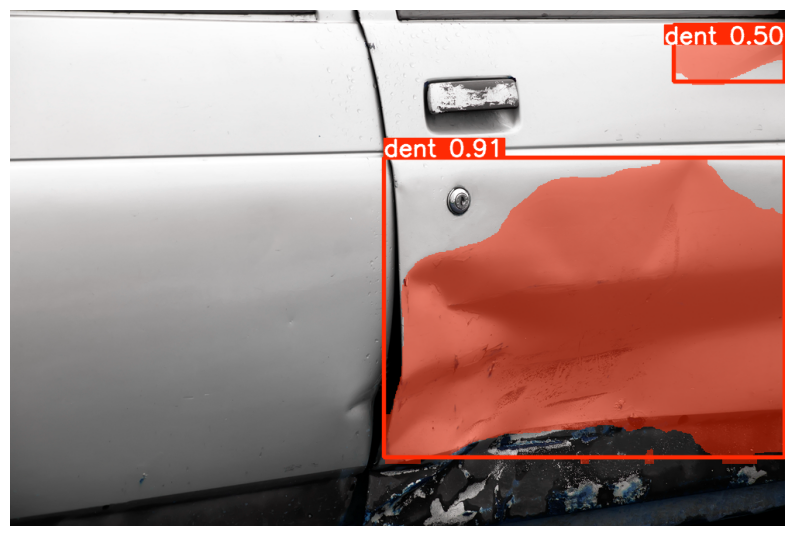


image 1/1 /content/CarDD_YOLO/test/images/002294.jpg: 448x640 1 dent, 4 scratchs, 1 crack, 37.9ms
Speed: 4.1ms preprocess, 37.9ms inference, 3.2ms postprocess per image at shape (1, 3, 448, 640)


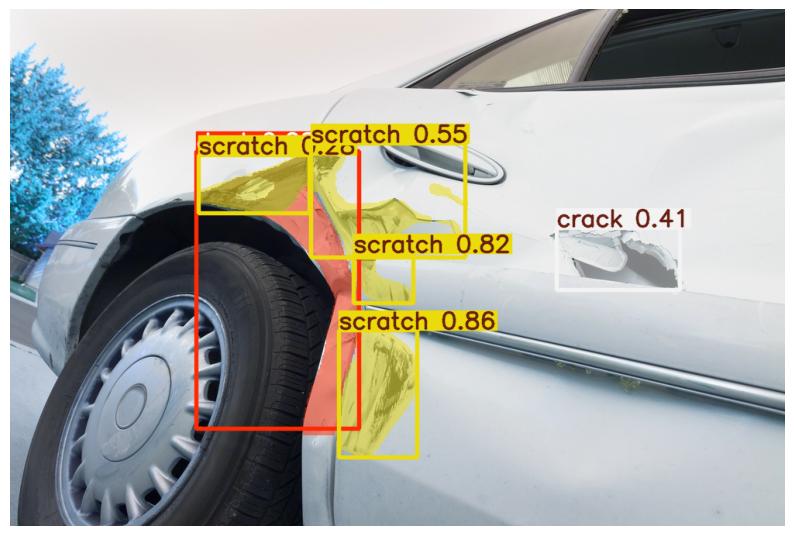


image 1/1 /content/CarDD_YOLO/test/images/002194.jpg: 448x640 1 scratch, 37.9ms
Speed: 50.6ms preprocess, 37.9ms inference, 4.7ms postprocess per image at shape (1, 3, 448, 640)


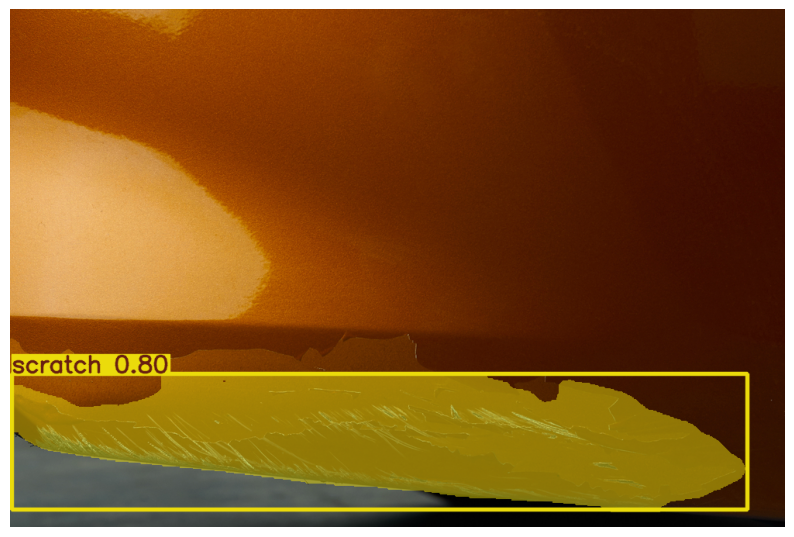

In [ ]:
from ultralytics import YOLO
import glob
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load your best model
model = YOLO('/content/drive/MyDrive/CarDD_v11_Results/car_damage_balanced_run/weights/best.pt')

# 2. Get a few images from the TEST set
test_images = glob.glob("/content/CarDD_YOLO/test/images/*.jpg")[:3] # Taking first 3 images

# 3. Predict and Show
for img_path in test_images:
    results = model.predict(source=img_path, conf=0.25, save=False)

    # Plotting
    res_plotted = results[0].plot()
    plt.figure(figsize=(10,10))
    plt.imshow(res_plotted)
    plt.axis('off')
    plt.show()

In [ ]:
from google.colab import files
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow
from PIL import Image
import numpy as np

# 1. Load your best trained model (now a segmentation model)
model_path = '/content/drive/MyDrive/CarDD_v11_Results/car_damage_balanced_run/weights/best.pt'
model = YOLO(model_path)

# 2. Create the Upload Button
print("Please upload your car damage image(s):")
uploaded = files.upload()

# 3. Process the uploaded files
for filename in uploaded.keys():
    print(f'Analyzing: "{filename}"')

    # Run prediction
    results = model.predict(source=filename, conf=0.25)

    # Plot results on the image (this will show colored masks)
    res_plotted = results[0].plot()

    # Show the image
    cv2_imshow(res_plotted)

    # --- ADDED MASK LOGIC HERE ---
    if results[0].masks is None or len(results[0].masks) == 0:
        print("No damage detected.")
    else:
        print(f"Found {len(results[0].masks)} damage masks!")

        # Loop through each detected damage to get details
        for i, mask in enumerate(results[0].masks):
            box = results[0].boxes[i]
            label = model.names[int(box.cls[0])]
            confidence = float(box.conf[0])

            # --- THE NEW ROBUST PIXEL CALCULATION ---
            m_binary = mask.data[0].cpu().numpy()
            m_scaled = cv2.resize(m_binary, (results[0].orig_shape[1], results[0].orig_shape[0]))
            pixel_area = int(np.sum(m_scaled > 0.5))
            # ----------------------------------------

            print(f" Damage {i+1}: {label.upper()}")
            print(f"   - Confidence: {confidence*100:.1f}%")
            print(f"   - Real-world Pixel Area: {pixel_area} px")

            # severity
            if pixel_area < 5000: # Note: These numbers will be much higher now!
                print("   - Severity: Minor")
            elif pixel_area < 20000:
                print("   - Severity: Moderate")
            else:
                print("   - Severity: Severe")

Please upload your car damage image(s):
